In [7]:
import os
import time
import warnings

import matplotlib.pyplot as plt

import torch
import torchvision.transforms.functional as F

from torch.export import export
from torchvision.io import decode_image

from executorch import version
from executorch.runtime import Runtime
from executorch.exir import to_edge_transform_and_lower
from executorch.backends.xnnpack.partition.xnnpack_partitioner import XnnpackPartitioner

from model import ssdlite320_mobilenet_v3_large, SSDLite320_MobileNet_V3_Large_Weights

warnings.simplefilter("ignore", FutureWarning)
print("Executorch version: ", version.__version__)

Executorch version:  1.1.0


In [2]:
WEIGHTS = SSDLite320_MobileNet_V3_Large_Weights.DEFAULT
CONSTRUCTOR = ssdlite320_mobilenet_v3_large

# Directory to save the exported .pte file
EXPORT_DIR = "exports"

# Path to the exported .pte file
MODEL_PATH: str

# Suffix for models
SUFFIX = "_xnnpack_fp32"

# Resize size for the input image, based on the name
RESIZE_SIZE = [320, 320]


# Based on the definition of the `transforms` field in the
# `SSDLite320_MobileNet_V3_Large_Weights` class
def preprocess(img: torch.Tensor) -> torch.Tensor:
    img = F.resize(img, RESIZE_SIZE)
    img = F.convert_image_dtype(img, torch.float)
    return img

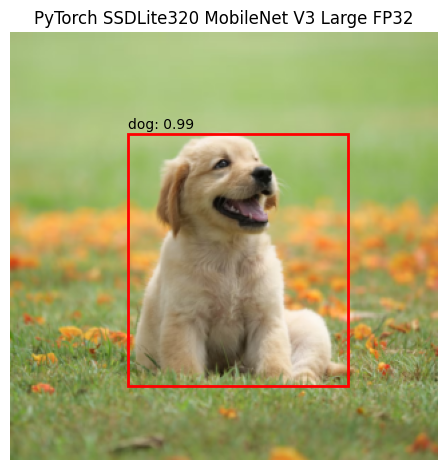

In [3]:
def visualize_predictions(img_tensor, prediction, score_threshold=0.5, title=""):
    categories = WEIGHTS.meta["categories"]
    # C,H,W float [0,1] → H,W,C numpy
    img_np = img_tensor.permute(1, 2, 0).detach().numpy().clip(0, 1)

    boxes = prediction["boxes"].detach()
    labels = prediction["labels"].detach()
    scores = prediction["scores"].detach()

    keep = scores > score_threshold
    boxes, labels, scores = boxes[keep], labels[keep], scores[keep]

    fig, ax = plt.subplots()
    ax.imshow(img_np)
    ax.set_title(title)
    ax.axis("off")

    for box, label, score in zip(boxes, labels, scores):
        x1, y1, x2, y2 = box.tolist()
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor="red", facecolor="none"))
        ax.text(x1, y1 - 4, f"{categories[int(label.item())]}: {score:.2f}")

    plt.tight_layout()
    plt.show()


model = CONSTRUCTOR(weights=WEIGHTS).eval()
img = decode_image("assets/dog.png")
img = preprocess(img)
visualize_predictions(img, model([img])[0], title="PyTorch SSDLite320 MobileNet V3 Large FP32")

In [4]:
model = CONSTRUCTOR(weights=WEIGHTS).eval()
inputs = ([torch.randn(3, *RESIZE_SIZE)],)

program = to_edge_transform_and_lower(export(model, inputs), partitioner=[XnnpackPartitioner()])
program = program.to_executorch()

with open(path := f"{EXPORT_DIR}/{CONSTRUCTOR.__name__}{SUFFIX}.pte", "wb") as f:
    MODEL_PATH = path
    f.write(program.buffer)

In [5]:
print("Verifying models...")

print(CONSTRUCTOR.__name__.upper())
path = MODEL_PATH

# --- ExecuTorch Inference ---
img = decode_image("assets/dog.png")
img = preprocess(img)
print(img.shape)

t = time.perf_counter()
runtime = Runtime.get()
program = runtime.load_program(path)
output = program.load_method("forward").execute([img])  # type: ignore
t = time.perf_counter() - t

print(
    f"Model size: {os.path.getsize(path) / 1024 / 1024:.2f}MB\n"
    f"Run successfully via ExecuTorch in {t:.2f} seconds."
)

# --- PyTorch Eager Reference ---
img = decode_image("assets/dog.png").unsqueeze(0)
img = F.resize(img, RESIZE_SIZE, interpolation=F.InterpolationMode.BILINEAR, antialias=True)

ref_model = CONSTRUCTOR(weights=WEIGHTS).eval()
ref_output = ref_model(WEIGHTS.transforms()(img))[0]

torch.testing.assert_close(output[0], ref_output["boxes"], rtol=1e-3, atol=1e-4)
torch.testing.assert_close(output[1], ref_output["scores"], rtol=1e-3, atol=1e-4)
torch.testing.assert_close(output[2], ref_output["labels"], rtol=1e-3, atol=1e-4)
print("Comparison passed!\n")

[program.cpp:154] InternalConsistency verification requested but not available
[cpuinfo_utils.cpp:71] Reading file /sys/devices/soc0/image_version
[cpuinfo_utils.cpp:87] Failed to open midr file /sys/devices/soc0/image_version
[cpuinfo_utils.cpp:167] Number of efficient cores 4


Verifying models...
SSDLITE320_MOBILENET_V3_LARGE
torch.Size([3, 320, 320])
Model size: 13.25MB
Run successfully via ExecuTorch in 0.04 seconds.
Comparison passed!



Visual inspection...


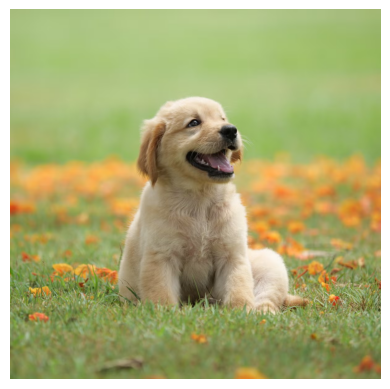

[program.cpp:154] InternalConsistency verification requested but not available


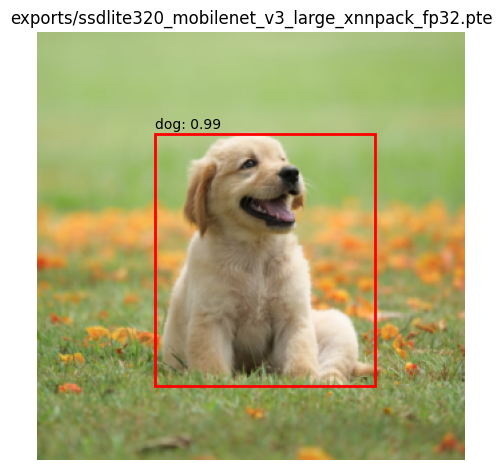

In [6]:
print("Visual inspection...")

img = decode_image("assets/dog.png")
plt.imshow(F.to_pil_image(img))
plt.axis("off")
plt.show()

img = decode_image("assets/dog.png")
img = preprocess(img)

path = MODEL_PATH
runtime = Runtime.get()
program = runtime.load_program(path)
output = program.load_method("forward").execute([img])  # type: ignore
visualize_predictions(img, {"boxes": output[0], "scores": output[1], "labels": output[2]}, title=path)